# Predicting 30-Day Hospital Readmission in Diabetic Patients

Dataset: *Diabetes 130-US Hospitals for Years 1999-2008* (UCI, CC BY 4.0).

Task: binary classification, `<30` days readmission (1) vs everything else (0).

## Environment and Imports
Install the notebook's pinned dependencies, then import the libraries used for data handling, preprocessing, classical ML, deep learning, metrics, and plots.

In [43]:
%pip install -r "https://raw.githubusercontent.com/Linda5-umwali/diabetes-readmission-prediction/main/requirements.txt"
import os
import random
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread
import lightgbm as lgb

import tensorflow as tf
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             recall_score, precision_score, confusion_matrix)

print("All main libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("Scikit-learn version:", sklearn.__version__)

SEED = 42
np.random.seed(SEED)
DATA_PATH = "diabetic_data.csv"

All main libraries imported successfully!
TensorFlow version: 2.21.0
Scikit-learn version: 1.6.1


## Inspecting the raw dataset
Load the CSV without automatically converting the dataset's "?" markers to missing values, then inspect its dimensions and the original readmitted label distribution.

OUTPUT: the shape gives the number of encounters and columns before cleaning. The value counts show how common each original readmission category is; this is important because readmission is imbalanced, so accuracy alone can later be misleading.

In [44]:
raw = pd.read_csv(DATA_PATH, keep_default_na=False)
print("Raw shape:", raw.shape)
raw["readmitted"].value_counts()

Raw shape: (101766, 50)


,count
readmitted,
NO,54864
>30,35545
<30,11357


## Clean the data and create the target
We use 1 for readmission within 30 days and 0 for the other two categories. We remove columns that are mostly missing or constant, and mark ? values as missing so the preprocessing step can handle them. We exclude encounters ending in death or hospice because they are not comparable to ordinary readmission cases.

This cell creates a working copy, remove encounters discharged to death or hospice, remove invalid gender records and columns that are not useful for this analysis, standardise unknown values, and reduce rare medical specialties into Other. The target is defined as readmission within 30 days versus other outcomes.

OUTPUT:Checks the number of removed encounters and the remaining row count. These cleaning choices affect which population the model represents; grouping rare specialties also reduces high-cardinality categories and sparse one-hot features.

In [45]:
df = raw.copy()

# Remove encounters ending in death or hospice
DEAD_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
n0 = len(df)
df = df[~df["discharge_disposition_id"].isin(DEAD_OR_HOSPICE)]
print("Removed death/hospice encounters:", n0 - len(df))

df = df[df["gender"] != "Unknown/Invalid"]
df = df.drop(columns=["weight", "payer_code", "examide", "citoglipton"])

for col in ["race", "medical_specialty"]:
    df[col] = df[col].replace("?", "Unknown")

# Keep only the 10 most frequent specialties, group the rest (reduces cardinality)
top_spec = df["medical_specialty"].value_counts().head(10).index
df["medical_specialty"] = df["medical_specialty"].where(df["medical_specialty"].isin(top_spec), "Other")

# Binary target
df["target"] = (df["readmitted"] == "<30").astype(int)
print("Positive rate:", df["target"].mean().round(4))
print("Shape after cleaning:", df.shape)

Removed death/hospice encounters: 2423
Positive rate: 0.1139
Shape after cleaning: (99340, 47)


## Feature Engineering
Group ICD-9 diagnosis codes into broader diagnosis families and derive medication-related and prior-utilisation features. These features compress detailed codes into categories that may generalise better across encounters.

Important features: diag_1_grp, diag_2_grp, and diag_3_grp describe diagnosis families; prior_visits, n_meds_used, and n_meds_changed summarise previous utilisation and medication complexity. These are candidate predictors, not evidence of causation.

In [46]:
def icd9_group(code):
    if code in ("?", ""): return "Unknown"
    if code[0] in "VE": return "Other"
    try: v = float(code)
    except ValueError: return "Other"
    if 250 <= v < 251: return "Diabetes"
    if (390 <= v <= 459) or v == 785: return "Circulatory"
    if (460 <= v <= 519) or v == 786: return "Respiratory"
    if (520 <= v <= 579) or v == 787: return "Digestive"
    if 800 <= v <= 999: return "Injury"
    if 710 <= v <= 739: return "Musculoskeletal"
    if (580 <= v <= 629) or v == 788: return "Genitourinary"
    if 140 <= v <= 239: return "Neoplasms"
    return "Other"

MED_COLS = ['metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide',
            'glipizide','glyburide','tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol',
            'troglitazone','tolazamide','insulin','glyburide-metformin','glipizide-metformin',
            'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone']

def engineer(d):
    d = d.copy()
    d["age_num"] = d["age"].str.extract(r"\[(\d+)-")[0].astype(int) + 5
    for c in ["diag_1", "diag_2", "diag_3"]:
        d[c + "_grp"] = d[c].apply(icd9_group)
    d["prior_visits"] = d["number_outpatient"] + d["number_emergency"] + d["number_inpatient"]
    d["n_meds_used"] = (d[MED_COLS] != "No").sum(axis=1)
    d["n_meds_changed"] = d[MED_COLS].isin(["Up", "Down"]).sum(axis=1)
    for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
        d[c] = d[c].astype(str)
    return d

df = engineer(df)
df[["age_num", "diag_1_grp", "prior_visits", "n_meds_used", "n_meds_changed"]].head()

,age_num,diag_1_grp,prior_visits,n_meds_used,n_meds_changed
0,5,Diabetes,0,0,0
1,15,Other,0,1,1
2,25,Other,3,1,0
3,35,Other,0,1,1
4,45,Neoplasms,0,2,0


## Patient-level train/validation/test split
Split by patient_nbr rather than by encounter, creating separate training, validation, and test groups. The assertions check that no patient appears in more than one split.

In [47]:
groups = df["patient_nbr"]

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss1.split(df, groups=groups))
temp = df.iloc[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_rel, test_rel = next(gss2.split(temp, groups=temp["patient_nbr"]))

train, val, test = df.iloc[train_idx], temp.iloc[val_rel], temp.iloc[test_rel]

# Sanity checks: no patient appears in two splits
assert not set(train.patient_nbr) & set(val.patient_nbr)
assert not set(train.patient_nbr) & set(test.patient_nbr)
assert not set(val.patient_nbr) & set(test.patient_nbr)

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} rows={len(part):6d} patients={part.patient_nbr.nunique():6d} positive rate={part.target.mean():.3f}")

train rows= 69613 patients= 48990 positive rate=0.114
val   rows= 14868 patients= 10498 positive rate=0.116
test  rows= 14859 patients= 10499 positive rate=0.113


## Defining model inputs and preprocessing
Exclude identifiers, the target, raw age category, and raw diagnosis codes from the predictor set. Separate numeric and categorical columns; numeric values are median-imputed and standardised, while categories are one-hot encoded with infrequent levels grouped.

In [48]:
DROP = ["encounter_id", "patient_nbr", "readmitted", "target", "age", "diag_1", "diag_2", "diag_3"]

FEATURES = [c for c in df.columns if c not in DROP]

NUM = [c for c in FEATURES if pd.api.types.is_numeric_dtype(df[c])]
CAT = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(df[c])]
print(len(NUM), "numeric and", len(CAT), "categorical features")

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT),
    ])

X_train, y_train = train[FEATURES], train["target"]
X_val,   y_val   = val[FEATURES],   val["target"]

12 numeric and 34 categorical features


## Evaluation functions
Set up a results log and validation-probability store. The threshold helper selects the threshold that maximises validation F1, and the evaluation helper records thresholded metrics plus ranking metrics.

In [49]:
from sklearn.metrics import accuracy_score

results = []
val_probas = {}

def best_threshold(y_true, proba):
    ts = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y_true, proba >= t) for t in ts]
    return ts[int(np.argmax(f1s))]

def evaluate_proba(name, proba, params, notes=""):
    val_probas[name] = proba
    thr = best_threshold(y_val, proba)
    pred = (proba >= thr).astype(int)
    row = {
        "Experiment": name, "Settings": params,
        "Accuracy": round(accuracy_score(y_val, pred), 4),
        "PR-AUC": round(average_precision_score(y_val, proba), 4),
        "ROC-AUC": round(roc_auc_score(y_val, proba), 4),
        "Macro-F1": round(f1_score(y_val, pred, average="macro"), 4),
        "Recall(<30)": round(recall_score(y_val, pred), 4),
        "Precision(<30)": round(precision_score(y_val, pred), 4),
        "Threshold": round(thr, 2), "Notes": notes,
    }
    results.append(row)
    print(confusion_matrix(y_val, pred))
    return pd.DataFrame([row])

def evaluate(name, model, params, notes=""):
    return evaluate_proba(name, model.predict_proba(X_val)[:, 1], params, notes)

# Experiments

## Experiment 1: Logistic Regression baseline
A simple, interpretable linear baseline with class weighting to account for the 11% positive class.

It fits a class-weighted Logistic Regression pipeline using the shared preprocessing steps. This is a relatively simple, interpretable baseline against which more flexible models can be compared.

In [50]:
lr = Pipeline([("prep", make_preprocessor()),
               ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))])
lr.fit(X_train, y_train)
evaluate("Exp1 Logistic Regression", lr, "class_weight=balanced, C=1.0", "Linear baseline")

[[10958  2192]
 [ 1085   633]]


,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp1 Logistic Regression,"class_weight=balanced, C=1.0",0.7796,0.221,0.6661,0.5743,0.3685,0.2241,0.57,Linear baseline


## Experiment 2: Random Forest (untuned baseline)
Trainined a 200-tree Random Forest with a minimum leaf size of five and balanced subsample weights. The forest can learn nonlinear relationships and interactions that a linear model may miss.

In [51]:
rf = Pipeline([("prep", make_preprocessor()),
               ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                              n_jobs=-1, random_state=SEED))])
rf.fit(X_train, y_train)
evaluate("Exp2 Random Forest", rf, "n_estimators=200, min_samples_leaf=5, class_weight=balanced_subsample", "Non-linear baseline")

[[9431 3719]
 [ 823  895]]


,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp2 Random Forest,"n_estimators=200, min_samples_leaf=5, class_weight=balan...",0.6945,0.227,0.6689,0.5443,0.521,0.194,0.35,Non-linear baseline


## Experiment 3: Feature-engineering ablation (Random Forest)
To show that the engineered features really help, I retrain the Experiment 2 model **without** these (diagnosis groups, `prior_visits`, `n_meds_used`, `n_meds_changed`) and compare. Only the features change; everything else (split, model, settings) stays identical.

In [52]:
ENGINEERED = ["diag_1_grp", "diag_2_grp", "diag_3_grp", "prior_visits", "n_meds_used", "n_meds_changed"]

def make_preprocessor_for(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat_cols),
    ])

NUM_ABL = [c for c in NUM if c not in ENGINEERED]
CAT_ABL = [c for c in CAT if c not in ENGINEERED]
FEATS_ABL = NUM_ABL + CAT_ABL

rf_abl = Pipeline([("prep", make_preprocessor_for(NUM_ABL, CAT_ABL)),
                   ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))])
rf_abl.fit(X_train[FEATS_ABL], y_train)

# evaluate() uses the global X_val, so temporarily wrap the model to select columns
class ColSelect:
    def __init__(self, model, cols): self.model, self.cols = model, cols
    def predict_proba(self, X): return self.model.predict_proba(X[self.cols])

evaluate("Exp3 RF without engineered features", ColSelect(rf_abl, FEATS_ABL),
         "same as Exp2, minus 6 engineered features", "Ablation: effect of feature engineering")

[[9832 3318]
 [ 906  812]]


,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp3 RF without engineered features,"same as Exp2, minus 6 engineered features",0.7159,0.2205,0.6597,0.5504,0.4726,0.1966,0.4,Ablation: effect of feature engineering


## Experiment 4: Tuned LightGBM (patient-grouped cross-validation)
Gradient boosting usually beats a Random Forest on tabular data. We tune it with `RandomizedSearchCV`, scoring by PR-AUC (`average_precision`), which suits the 11% positive class. Cross-validation uses `GroupKFold` on `patient_nbr` so the same patient never appears in both the training and validation folds of a split.

In [75]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

lgbm_pipe = Pipeline([("prep", make_preprocessor()),
                      ("clf", LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1,
                                              class_weight="balanced"))])

param_dist = {
    "clf__n_estimators": [200, 400, 600],
    "clf__learning_rate": [0.02, 0.05, 0.1],
    "clf__num_leaves": [15, 31, 63],
    "clf__min_child_samples": [20, 50, 100],
    "clf__subsample": [0.7, 0.9, 1.0],
    "clf__subsample_freq": [1],
    "clf__colsample_bytree": [0.5, 0.8, 1.0],
    "clf__reg_lambda": [0.0, 1.0, 5.0],
}

cv = GroupKFold(n_splits=3)
search = RandomizedSearchCV(lgbm_pipe, param_dist, n_iter=12, scoring="average_precision",
                            cv=cv, random_state=SEED, n_jobs=1, verbose=1)
search.fit(X_train, y_train, groups=train["patient_nbr"])

print("Best CV PR-AUC:", round(search.best_score_, 4))
print("Best params:", search.best_params_)
best_lgbm = search.best_estimator_
evaluate("Exp4 LightGBM (tuned)", best_lgbm, str(search.best_params_), "RandomizedSearchCV, 12 draws, 3 grouped folds")

Fitting 3 folds for each of 12 candidates, totalling 36 fits


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Best CV PR-AUC: 0.2241
Best params: {'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__reg_lambda': 1.0, 'clf__num_leaves': 63, 'clf__n_estimators': 400, 'clf__min_child_samples': 50, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.5}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[[10410  2740]
 [  978   740]]


,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp4 LightGBM (tuned),"{'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__...",0.7499,0.2384,0.6756,0.5666,0.4307,0.2126,0.54,"RandomizedSearchCV, 12 draws, 3 grouped folds"


## evaluate and save the tuned LightGBM model
Saves the tuned pipeline and evaluate it on the validation set using the shared metrics and validation-selected threshold.

In [76]:
import joblib

joblib.dump(best_lgbm, "best_traditional_model.joblib")
evaluate("Exp4 LightGBM (tuned)", best_lgbm, str(search.best_params_),
         "RandomizedSearchCV, 12 draws, 3 grouped folds")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[[10410  2740]
 [  978   740]]


,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp4 LightGBM (tuned),"{'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__...",0.7499,0.2384,0.6756,0.5666,0.4307,0.2126,0.54,"RandomizedSearchCV, 12 draws, 3 grouped folds"


## Experiment 5: Imbalance handling (class weights vs none)
I retrain the best LightGBM configuration **without** class weighting to see how much the weighting contributes. Class weights change the model's probability scale, but our threshold is re-tuned on the validation set, so the comparison is fair.

In [54]:
no_weight = Pipeline([("prep", make_preprocessor()),
                      ("clf", LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1, class_weight=None))])
no_weight.set_params(**{k: v for k, v in search.best_params_.items()})
no_weight.fit(X_train, y_train)
evaluate("Exp5 LightGBM, no class weights", no_weight, "best Exp4 params, class_weight=None", "Effect of class weighting")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[[10328  2822]
 [  960   758]]


,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,"Exp5 LightGBM, no class weights","best Exp4 params, class_weight=None",0.7456,0.2385,0.6748,0.5657,0.4412,0.2117,0.14,Effect of class weighting


## validation results
Display the accumulated experiment metrics in one table.

In [77]:
res = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 60)
res

,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp1 Logistic Regression,"class_weight=balanced, C=1.0",0.7796,0.2210,0.6661,0.5743,0.3685,0.2241,0.57,Linear baseline
1,Exp2 Random Forest,"n_estimators=200, min_samples_leaf=5, class_weight=balan...",0.6945,0.2270,0.6689,0.5443,0.5210,0.1940,0.35,Non-linear baseline
2,Exp3 RF without engineered features,"same as Exp2, minus 6 engineered features",0.7159,0.2205,0.6597,0.5504,0.4726,0.1966,0.40,Ablation: effect of feature engineering
3,Exp4 LightGBM (tuned),"{'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__...",0.7499,0.2384,0.6756,0.5666,0.4307,0.2126,0.54,"RandomizedSearchCV, 12 draws, 3 grouped folds"
4,"Exp5 LightGBM, no class weights","best Exp4 params, class_weight=None",0.7456,0.2385,0.6748,0.5657,0.4412,0.2117,0.14,Effect of class weighting
5,Exp6 Sequential MLP,"Dense 128-64, Adam 1e-3, batch 512, class weights, early...",0.7277,0.2258,0.6687,0.5580,0.4680,0.2041,0.55,DL baseline (Sequential API)
6,Exp7 Embedding model,"Functional API, embeddings (dim<=8), Dense 128-64, Adam ...",0.7087,0.2280,0.6682,0.5500,0.4971,0.1976,0.53,Architecture change: embeddings
7,Exp8 Embedding + regularisation,"as Exp7 + dropout 0.3, L2 1e-4, batch norm",0.7180,0.2337,0.6722,0.5556,0.4913,0.2027,0.55,Regularisation to reduce overfitting
8,Exp9 Embedding + LR schedule,"Dense 256-128, dropout 0.4, L2 1e-4, BN, Adam 3e-3 + Red...",0.7538,0.2355,0.6742,0.5709,0.4366,0.2179,0.54,Wider net + LR schedule
9,Exp4 LightGBM (tuned),"{'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__...",0.7499,0.2384,0.6756,0.5666,0.4307,0.2126,0.54,"RandomizedSearchCV, 12 draws, 3 grouped folds"


## Compare classical models using validation curves
This cell generates validation-set precision–recall and ROC curves from predicted probabilities for the classical experiments.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


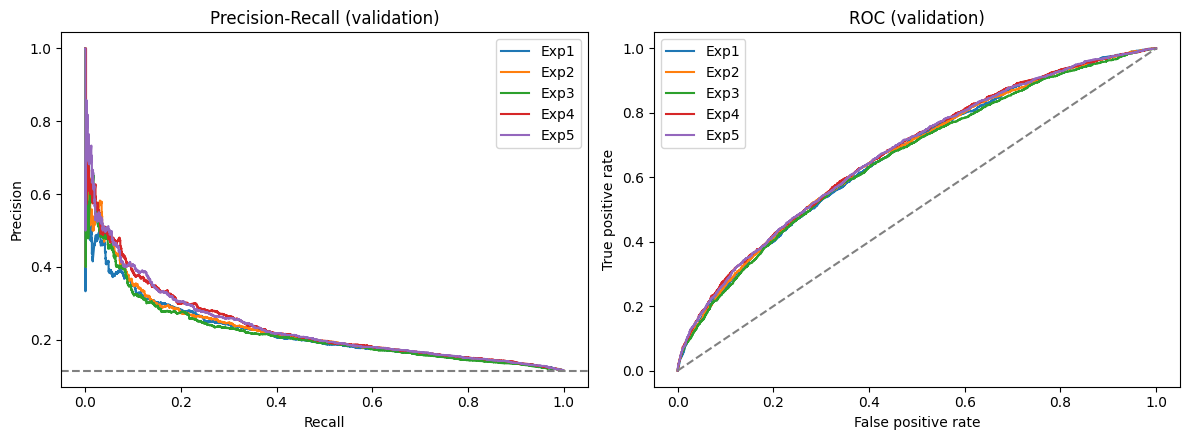

In [56]:
from sklearn.metrics import precision_recall_curve, roc_curve

# Construct the missing val_probas dictionary with prediction probabilities on X_val
val_probas = {
    "Exp1 Logistic Regression": lr.predict_proba(X_val)[:, 1],
    "Exp2 Random Forest": rf.predict_proba(X_val)[:, 1],
    "Exp3 RF (Ablation)": rf_abl.predict_proba(X_val[FEATS_ABL])[:, 1],
    "Exp4 LightGBM (Tuned)": best_lgbm.predict_proba(X_val)[:, 1],
    "Exp5 LightGBM (No weights)": no_weight.predict_proba(X_val)[:, 1]
}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in val_probas.items():
    pr, rc, _ = precision_recall_curve(y_val, p); ax[0].plot(rc, pr, label=name.split(" ")[0])
    fpr, tpr, _ = roc_curve(y_val, p);            ax[1].plot(fpr, tpr, label=name.split(" ")[0])
ax[0].axhline(y_val.mean(), ls="--", c="grey"); ax[0].set(title="Precision-Recall (validation)", xlabel="Recall", ylabel="Precision")
ax[1].plot([0, 1], [0, 1], ls="--", c="grey");   ax[1].set(title="ROC (validation)", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

# Deep learning: data preparation with `tf.data`
For the neural networks I reuse the **same patient-level split**. Two input formats are prepared:
1. A dense matrix (scaled numbers + one-hot categories) for the plain MLP.
2. A dictionary of inputs (one numeric block + one integer-coded column per categorical feature) for the embedding model. Index 0 is reserved for categories not seen in training.

Both are wrapped in `tf.data.Dataset` pipelines with shuffling, batching and prefetching. All encoders are fitted on the training set only.

In [57]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import OrdinalEncoder

keras.utils.set_random_seed(SEED)
BATCH = 512

# 1. dense matrix for the MLP
prep_dl = make_preprocessor().fit(X_train)
def to_dense(X):
    out = prep_dl.transform(X)
    return (out.toarray() if hasattr(out, "toarray") else np.asarray(out)).astype("float32")

Xtr_d, Xva_d = to_dense(X_train), to_dense(X_val)
ytr, yva = y_train.values.astype("float32"), y_val.values.astype("float32")
print("Dense input shape:", Xtr_d.shape)

def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(20000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_ds(Xtr_d, ytr, shuffle=True), make_ds(Xva_d, yva)

# 2. dict inputs for the embedding model
num_prep = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]).fit(X_train[NUM])
ordenc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype="int64").fit(X_train[CAT])
card = [len(c) + 1 for c in ordenc.categories_]     # +1 for the "unknown" slot (index 0)

def make_ds_emb(X, y, shuffle=False):
    feats = {"num": num_prep.transform(X[NUM]).astype("float32")}
    cat = ordenc.transform(X[CAT]) + 1
    feats.update({f"cat_{i}": cat[:, i] for i in range(len(CAT))})
    ds = tf.data.Dataset.from_tensor_slices((feats, y))
    if shuffle:
        ds = ds.shuffle(20000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds_emb, val_ds_emb = make_ds_emb(X_train, ytr, shuffle=True), make_ds_emb(X_val, yva)

# Class weights for the 11% positive class
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
CLASS_WEIGHT = {0: 1.0, 1: float(neg / pos)}
print("Class weights:", CLASS_WEIGHT)

Dense input shape: (69613, 169)
Class weights: {0: 1.0, 1: 7.795072646873026}


## Training helper
One function trains, logs to TensorBoard, stops early when validation PR-AUC stops improving (and restores the best weights), and returns validation probabilities. View the logs with `%load_ext tensorboard` then `%tensorboard --logdir logs`.

In [58]:
METRICS = [keras.metrics.AUC(name="pr_auc", curve="PR"), keras.metrics.AUC(name="roc_auc")]
histories, dl_models = {}, {}

def run_dl(name, model, tr, va, epochs=40, lr=1e-3, class_weight=CLASS_WEIGHT, reduce_lr=False, patience=5):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=METRICS)
    cbs = [keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=patience, restore_best_weights=True),
           keras.callbacks.TensorBoard(log_dir="logs/" + name.replace(" ", "_"))]
    if reduce_lr:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=2, min_lr=1e-5))
    h = model.fit(tr, validation_data=va, epochs=epochs, class_weight=class_weight, callbacks=cbs, shuffle=False, verbose=2)
    histories[name], dl_models[name] = h.history, model
    return model.predict(va, verbose=0).ravel()

## Experiment 6: Sequential MLP baseline
A small two-hidden-layer network on the one-hot plus scaled features. It is the deep learning counterpart of the Logistic Regression baseline.

In [59]:
mlp = keras.Sequential([keras.Input((Xtr_d.shape[1],)),
                        layers.Dense(128, activation="relu"),
                        layers.Dense(64, activation="relu"),
                        layers.Dense(1, activation="sigmoid")])
p6 = run_dl("Exp6 Sequential MLP", mlp, train_ds, val_ds, lr=1e-3)
evaluate_proba("Exp6 Sequential MLP", p6, "Dense 128-64, Adam 1e-3, batch 512, class weights, early stopping", "DL baseline (Sequential API)")

Epoch 1/40
136/136 - 4s - 28ms/step - loss: 1.1705 - pr_auc: 0.1988 - roc_auc: 0.6417 - val_loss: 0.6380 - val_pr_auc: 0.2120 - val_roc_auc: 0.6609
Epoch 2/40
136/136 - 3s - 20ms/step - loss: 1.1473 - pr_auc: 0.2162 - roc_auc: 0.6687 - val_loss: 0.5970 - val_pr_auc: 0.2188 - val_roc_auc: 0.6671
Epoch 3/40
136/136 - 3s - 19ms/step - loss: 1.1382 - pr_auc: 0.2254 - roc_auc: 0.6786 - val_loss: 0.5951 - val_pr_auc: 0.2238 - val_roc_auc: 0.6710
Epoch 4/40
136/136 - 2s - 11ms/step - loss: 1.1285 - pr_auc: 0.2323 - roc_auc: 0.6871 - val_loss: 0.5805 - val_pr_auc: 0.2220 - val_roc_auc: 0.6676
Epoch 5/40
136/136 - 2s - 11ms/step - loss: 1.1191 - pr_auc: 0.2413 - roc_auc: 0.6953 - val_loss: 0.6227 - val_pr_auc: 0.2255 - val_roc_auc: 0.6687
Epoch 6/40
136/136 - 1s - 11ms/step - loss: 1.1106 - pr_auc: 0.2484 - roc_auc: 0.7030 - val_loss: 0.6058 - val_pr_auc: 0.2221 - val_roc_auc: 0.6659
Epoch 7/40
136/136 - 1s - 10ms/step - loss: 1.1042 - pr_auc: 0.2538 - roc_auc: 0.7084 - val_loss: 0.5531 - val_p

,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp6 Sequential MLP,"Dense 128-64, Adam 1e-3, batch 512, class weights, early...",0.7277,0.2258,0.6687,0.558,0.468,0.2041,0.55,DL baseline (Sequential API)


## Experiment 7: Functional API with embeddings
One-hot encoding treats every category as an unrelated column. An embedding layer instead learns a small dense vector for each category (for example, each diagnosis group or specialty), so similar categories can end up close together. The numeric features pass through a dense layer and are concatenated with all the embeddings.

In [60]:
def build_embedding_model(units=(128, 64), dropout=0.0, l2=0.0, batchnorm=False):
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    num_in = keras.Input((len(NUM),), name="num")
    cat_in = [keras.Input((), dtype="int64", name=f"cat_{i}") for i in range(len(CAT))]
    embs = [layers.Embedding(card[i], min(8, (card[i] + 1) // 2))(inp) for i, inp in enumerate(cat_in)]
    x = layers.Concatenate()([num_in] + embs)
    for u in units:
        x = layers.Dense(u, activation="relu", kernel_regularizer=reg)(x)
        if batchnorm: x = layers.BatchNormalization()(x)
        if dropout > 0: x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model([num_in] + cat_in, out)

emb7 = build_embedding_model()
p7 = run_dl("Exp7 Embedding model", emb7, train_ds_emb, val_ds_emb, lr=1e-3)
evaluate_proba("Exp7 Embedding model", p7, "Functional API, embeddings (dim<=8), Dense 128-64, Adam 1e-3", "Architecture change: embeddings")

Epoch 1/40
136/136 - 16s - 121ms/step - loss: 1.1720 - pr_auc: 0.1997 - roc_auc: 0.6404 - val_loss: 0.6493 - val_pr_auc: 0.2091 - val_roc_auc: 0.6566
Epoch 2/40
136/136 - 5s - 33ms/step - loss: 1.1492 - pr_auc: 0.2153 - roc_auc: 0.6677 - val_loss: 0.6617 - val_pr_auc: 0.2193 - val_roc_auc: 0.6677
Epoch 3/40
136/136 - 7s - 48ms/step - loss: 1.1414 - pr_auc: 0.2214 - roc_auc: 0.6758 - val_loss: 0.6377 - val_pr_auc: 0.2221 - val_roc_auc: 0.6718
Epoch 4/40
136/136 - 5s - 33ms/step - loss: 1.1366 - pr_auc: 0.2248 - roc_auc: 0.6798 - val_loss: 0.5955 - val_pr_auc: 0.2227 - val_roc_auc: 0.6703
Epoch 5/40
136/136 - 5s - 40ms/step - loss: 1.1329 - pr_auc: 0.2293 - roc_auc: 0.6833 - val_loss: 0.5842 - val_pr_auc: 0.2232 - val_roc_auc: 0.6704
Epoch 6/40
136/136 - 9s - 67ms/step - loss: 1.1292 - pr_auc: 0.2314 - roc_auc: 0.6868 - val_loss: 0.5915 - val_pr_auc: 0.2233 - val_roc_auc: 0.6698
Epoch 7/40
136/136 - 7s - 51ms/step - loss: 1.1247 - pr_auc: 0.2341 - roc_auc: 0.6903 - val_loss: 0.6616 - val

,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp7 Embedding model,"Functional API, embeddings (dim<=8), Dense 128-64, Adam ...",0.7087,0.228,0.6682,0.55,0.4971,0.1976,0.53,Architecture change: embeddings


## Experiment 8: Regularisation
 Here we add dropout, L2 weight decay and batch normalisation to reduce variance.

In [61]:
emb8 = build_embedding_model(dropout=0.3, l2=1e-4, batchnorm=True)
p8 = run_dl("Exp8 Embedding + regularisation", emb8, train_ds_emb, val_ds_emb, lr=1e-3)
evaluate_proba("Exp8 Embedding + regularisation", p8, "as Exp7 + dropout 0.3, L2 1e-4, batch norm", "Regularisation to reduce overfitting")

Epoch 1/40
136/136 - 17s - 122ms/step - loss: 1.3989 - pr_auc: 0.1553 - roc_auc: 0.5853 - val_loss: 0.6887 - val_pr_auc: 0.1939 - val_roc_auc: 0.6298
Epoch 2/40
136/136 - 8s - 56ms/step - loss: 1.2637 - pr_auc: 0.1726 - roc_auc: 0.6090 - val_loss: 0.6856 - val_pr_auc: 0.1988 - val_roc_auc: 0.6495
Epoch 3/40
136/136 - 6s - 44ms/step - loss: 1.2182 - pr_auc: 0.1820 - roc_auc: 0.6315 - val_loss: 0.6730 - val_pr_auc: 0.2110 - val_roc_auc: 0.6604
Epoch 4/40
136/136 - 4s - 32ms/step - loss: 1.1933 - pr_auc: 0.1954 - roc_auc: 0.6480 - val_loss: 0.6635 - val_pr_auc: 0.2115 - val_roc_auc: 0.6646
Epoch 5/40
136/136 - 4s - 33ms/step - loss: 1.1838 - pr_auc: 0.2002 - roc_auc: 0.6528 - val_loss: 0.6530 - val_pr_auc: 0.2162 - val_roc_auc: 0.6670
Epoch 6/40
136/136 - 6s - 47ms/step - loss: 1.1735 - pr_auc: 0.2091 - roc_auc: 0.6606 - val_loss: 0.6588 - val_pr_auc: 0.2212 - val_roc_auc: 0.6703
Epoch 7/40
136/136 - 4s - 33ms/step - loss: 1.1661 - pr_auc: 0.2144 - roc_auc: 0.6682 - val_loss: 0.6561 - val

,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp8 Embedding + regularisation,"as Exp7 + dropout 0.3, L2 1e-4, batch norm",0.718,0.2337,0.6722,0.5556,0.4913,0.2027,0.55,Regularisation to reduce overfitting


## Experiment 9: Optimisation (wider network, learning-rate)
A larger network with stronger dropout, a higher starting learning rate, and `ReduceLROnPlateau`, which halves the learning rate when validation PR-AUC stops improving. A high rate early speeds up learning, and the lower rate later allows fine adjustment.

In [62]:
emb9 = build_embedding_model(units=(256, 128), dropout=0.4, l2=1e-4, batchnorm=True)
p9 = run_dl("Exp9 Embedding + LR schedule", emb9, train_ds_emb, val_ds_emb, lr=3e-3, reduce_lr=True, patience=6)
evaluate_proba("Exp9 Embedding + LR schedule", p9, "Dense 256-128, dropout 0.4, L2 1e-4, BN, Adam 3e-3 + ReduceLROnPlateau", "Wider net + LR schedule")

Epoch 1/40
136/136 - 16s - 118ms/step - loss: 1.3154 - pr_auc: 0.1681 - roc_auc: 0.6140 - val_loss: 0.6390 - val_pr_auc: 0.2033 - val_roc_auc: 0.6566 - learning_rate: 0.0030
Epoch 2/40
136/136 - 7s - 52ms/step - loss: 1.1936 - pr_auc: 0.2023 - roc_auc: 0.6554 - val_loss: 0.6657 - val_pr_auc: 0.2136 - val_roc_auc: 0.6662 - learning_rate: 0.0030
Epoch 3/40
136/136 - 5s - 39ms/step - loss: 1.1781 - pr_auc: 0.2110 - roc_auc: 0.6658 - val_loss: 0.6567 - val_pr_auc: 0.2217 - val_roc_auc: 0.6665 - learning_rate: 0.0030
Epoch 4/40
136/136 - 6s - 46ms/step - loss: 1.1767 - pr_auc: 0.2094 - roc_auc: 0.6677 - val_loss: 0.6418 - val_pr_auc: 0.2243 - val_roc_auc: 0.6725 - learning_rate: 0.0030
Epoch 5/40
136/136 - 6s - 46ms/step - loss: 1.1724 - pr_auc: 0.2133 - roc_auc: 0.6686 - val_loss: 0.6521 - val_pr_auc: 0.2245 - val_roc_auc: 0.6712 - learning_rate: 0.0030
Epoch 6/40
136/136 - 6s - 41ms/step - loss: 1.1698 - pr_auc: 0.2153 - roc_auc: 0.6696 - val_loss: 0.6587 - val_pr_auc: 0.2252 - val_roc_au

,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp9 Embedding + LR schedule,"Dense 256-128, dropout 0.4, L2 1e-4, BN, Adam 3e-3 + Red...",0.7538,0.2355,0.6742,0.5709,0.4366,0.2179,0.54,Wider net + LR schedule


## Learning curves and saving the best deep learning model
Plot training versus validation loss and PR-AUC for each deep-learning experiment. The code then identifies the neural model with the highest recorded validation PR-AUC and saves it.

Comparing training and validation curves for each run. A widening gap between them signals overfitting (high variance); both curves staying poor signals underfitting (high bias).

OUTPUT: In the current recorded results, Experiment 9 is selected as the best deep-learning model by validation PR-AUC. This selection is based on validation data, not the test set.

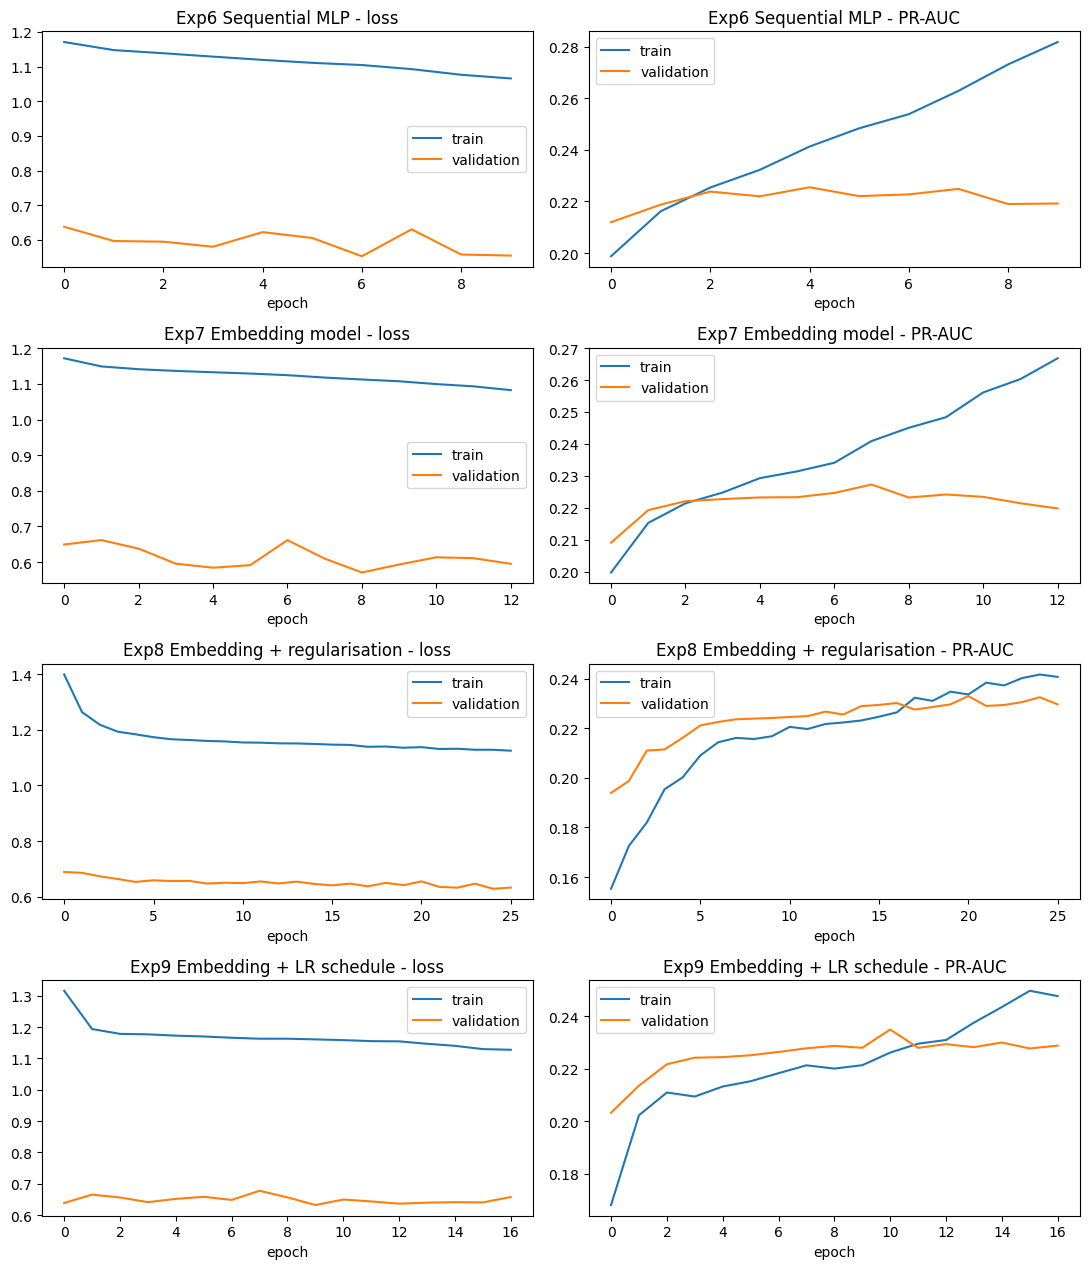

Best DL model: Exp9 Embedding + LR schedule


In [63]:
fig, axes = plt.subplots(len(histories), 2, figsize=(11, 3.2 * len(histories)))
for row, (name, h) in zip(np.atleast_2d(axes), histories.items()):
    row[0].plot(h["loss"], label="train"); row[0].plot(h["val_loss"], label="validation")
    row[0].set(title=name + " - loss", xlabel="epoch"); row[0].legend()
    row[1].plot(h["pr_auc"], label="train"); row[1].plot(h["val_pr_auc"], label="validation")
    row[1].set(title=name + " - PR-AUC", xlabel="epoch"); row[1].legend()
plt.tight_layout(); plt.show()

# Save the best DL model (by validation PR-AUC) for the Google Drive folder
dl_rows = [r for r in results if r["Experiment"].startswith(("Exp6", "Exp7", "Exp8", "Exp9"))]
best_dl = max(dl_rows, key=lambda r: r["PR-AUC"])["Experiment"]
print("Best DL model:", best_dl)
dl_models[best_dl].save("best_dl_model.keras")

# Results table and curves
Display the accumulated results table, including repeated evaluation rows if the same experiment was logged more than once.

In [79]:
res = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 60)
res

,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp1 Logistic Regression,"class_weight=balanced, C=1.0",0.7796,0.2210,0.6661,0.5743,0.3685,0.2241,0.57,Linear baseline
1,Exp2 Random Forest,"n_estimators=200, min_samples_leaf=5, class_weight=balan...",0.6945,0.2270,0.6689,0.5443,0.5210,0.1940,0.35,Non-linear baseline
2,Exp3 RF without engineered features,"same as Exp2, minus 6 engineered features",0.7159,0.2205,0.6597,0.5504,0.4726,0.1966,0.40,Ablation: effect of feature engineering
3,Exp4 LightGBM (tuned),"{'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__...",0.7499,0.2384,0.6756,0.5666,0.4307,0.2126,0.54,"RandomizedSearchCV, 12 draws, 3 grouped folds"
4,"Exp5 LightGBM, no class weights","best Exp4 params, class_weight=None",0.7456,0.2385,0.6748,0.5657,0.4412,0.2117,0.14,Effect of class weighting
5,Exp6 Sequential MLP,"Dense 128-64, Adam 1e-3, batch 512, class weights, early...",0.7277,0.2258,0.6687,0.5580,0.4680,0.2041,0.55,DL baseline (Sequential API)
6,Exp7 Embedding model,"Functional API, embeddings (dim<=8), Dense 128-64, Adam ...",0.7087,0.2280,0.6682,0.5500,0.4971,0.1976,0.53,Architecture change: embeddings
7,Exp8 Embedding + regularisation,"as Exp7 + dropout 0.3, L2 1e-4, batch norm",0.7180,0.2337,0.6722,0.5556,0.4913,0.2027,0.55,Regularisation to reduce overfitting
8,Exp9 Embedding + LR schedule,"Dense 256-128, dropout 0.4, L2 1e-4, BN, Adam 3e-3 + Red...",0.7538,0.2355,0.6742,0.5709,0.4366,0.2179,0.54,Wider net + LR schedule
9,Exp4 LightGBM (tuned),"{'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__...",0.7499,0.2384,0.6756,0.5666,0.4307,0.2126,0.54,"RandomizedSearchCV, 12 draws, 3 grouped folds"


## creating a clean results table and export it
Keep the first recorded row for each experiment, reset the index, save the table as a CSV, and display the deduplicated comparison.

In [80]:
res = pd.DataFrame(results).drop_duplicates(subset="Experiment", keep="first").reset_index(drop=True)
res.to_csv("/content/drive/MyDrive/diabetes_readmission_outputs/results.csv", index=False)
res

,Experiment,Settings,Accuracy,PR-AUC,ROC-AUC,Macro-F1,Recall(<30),Precision(<30),Threshold,Notes
0,Exp1 Logistic Regression,"class_weight=balanced, C=1.0",0.7796,0.2210,0.6661,0.5743,0.3685,0.2241,0.57,Linear baseline
1,Exp2 Random Forest,"n_estimators=200, min_samples_leaf=5, class_weight=balan...",0.6945,0.2270,0.6689,0.5443,0.5210,0.1940,0.35,Non-linear baseline
2,Exp3 RF without engineered features,"same as Exp2, minus 6 engineered features",0.7159,0.2205,0.6597,0.5504,0.4726,0.1966,0.40,Ablation: effect of feature engineering
3,Exp4 LightGBM (tuned),"{'clf__subsample_freq': 1, 'clf__subsample': 0.9, 'clf__...",0.7499,0.2384,0.6756,0.5666,0.4307,0.2126,0.54,"RandomizedSearchCV, 12 draws, 3 grouped folds"
4,"Exp5 LightGBM, no class weights","best Exp4 params, class_weight=None",0.7456,0.2385,0.6748,0.5657,0.4412,0.2117,0.14,Effect of class weighting
5,Exp6 Sequential MLP,"Dense 128-64, Adam 1e-3, batch 512, class weights, early...",0.7277,0.2258,0.6687,0.5580,0.4680,0.2041,0.55,DL baseline (Sequential API)
6,Exp7 Embedding model,"Functional API, embeddings (dim<=8), Dense 128-64, Adam ...",0.7087,0.2280,0.6682,0.5500,0.4971,0.1976,0.53,Architecture change: embeddings
7,Exp8 Embedding + regularisation,"as Exp7 + dropout 0.3, L2 1e-4, batch norm",0.7180,0.2337,0.6722,0.5556,0.4913,0.2027,0.55,Regularisation to reduce overfitting
8,Exp9 Embedding + LR schedule,"Dense 256-128, dropout 0.4, L2 1e-4, BN, Adam 3e-3 + Red...",0.7538,0.2355,0.6742,0.5709,0.4366,0.2179,0.54,Wider net + LR schedule


## Comparing validation curves across models
Plot precision–recall and ROC curves for the available validation probabilities. The dashed PR baseline shows the validation readmission prevalence; the diagonal ROC line represents chance ranking.

OUTPUT: PR curves emphasise the precision/recall trade-off for the minority class, while ROC curves summarise ranking across thresholds.

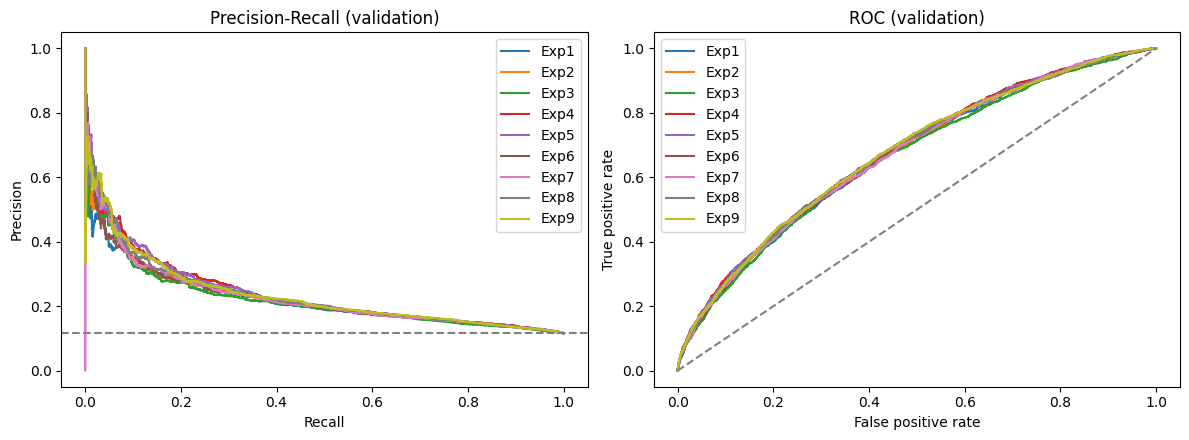

In [65]:
from sklearn.metrics import precision_recall_curve, roc_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in val_probas.items():
    pr, rc, _ = precision_recall_curve(y_val, p); ax[0].plot(rc, pr, label=name.split(" ")[0])
    fpr, tpr, _ = roc_curve(y_val, p);            ax[1].plot(fpr, tpr, label=name.split(" ")[0])
ax[0].axhline(y_val.mean(), ls="--", c="grey"); ax[0].set(title="Precision-Recall (validation)", xlabel="Recall", ylabel="Precision")
ax[1].plot([0, 1], [0, 1], ls="--", c="grey");   ax[1].set(title="ROC (validation)", xlabel="False positive rate", ylabel="True positive rate")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

## 20. Final evaluation on the held-out test set
Generates test probabilities for the tuned LightGBM model and the best neural model, apply thresholds selected on validation, and calculate test metrics plus a patient-level bootstrap confidence interval for PR-AUC.

OUTPUT Results: the test table reports LightGBM PR-AUC of 0.2432 (95% bootstrap CI 0.216–0.280) and the selected neural model PR-AUC of 0.2383 (95% CI 0.214–0.276). Their intervals overlap, so these results do not show a clear PR-AUC advantage for either model. The majority-only baseline's high accuracy reflects class imbalance.

In [66]:
Mfrom sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, accuracy_score, average_precision_score, roc_auc_score, f1_score, recall_score, precision_score

X_test, y_test = test[FEATURES], test["target"].values
test_meta = test.reset_index(drop=True)

# predictions of the two chosen models on the test set
def predict_dl_test(name):
    if name.startswith("Exp6"):
        return dl_models[name].predict(to_dense(X_test), verbose=0).ravel()
    ds = make_ds_emb(X_test, y_test.astype("float32"))
    return dl_models[name].predict(ds, verbose=0).ravel()

CLASSICAL = "Exp4 LightGBM (tuned)"
DEEP = best_dl
test_probas = {CLASSICAL: best_lgbm.predict_proba(X_test)[:, 1], DEEP: predict_dl_test(DEEP)}

# Aligning keys of val_probas with test_probas ignoring case differences
val_probas_clean = {k.lower().strip(): v for k, v in val_probas.items()}
thr = {n: best_threshold(y_val, val_probas_clean[n.lower().strip()]) for n in test_probas}

def bootstrap_ci(y, p, groups, n_boot=200, seed=SEED):
    rng = np.random.default_rng(seed)
    idx_by = pd.Series(np.arange(len(y))).groupby(np.asarray(groups)).apply(lambda s: s.values)
    vals = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(idx_by), len(idx_by))
        idx = np.concatenate([idx_by.iloc[i] for i in pick])
        if y[idx].sum() > 0:
            vals.append(average_precision_score(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

rows = []
for name, p in test_probas.items():
    pred = (p >= thr[name]).astype(int)
    lo, hi = bootstrap_ci(y_test, p, test_meta["patient_nbr"])
    rows.append({"Model": name, "Threshold (from val)": round(thr[name], 2),
                 "Accuracy": round(accuracy_score(y_test, pred), 4),
                 "PR-AUC": round(average_precision_score(y_test, p), 4),
                 "PR-AUC 95% CI": f"{lo:.3f}-{hi:.3f}",
                 "ROC-AUC": round(roc_auc_score(y_test, p), 4),
                 "Macro-F1": round(f1_score(y_test, pred, average="macro"), 4),
                 "Recall(<30)": round(recall_score(y_test, pred), 4),
                 "Precision(<30)": round(precision_score(y_test, pred), 4)})
rows.append({"Model": "Baseline: predict nobody readmitted", "Accuracy": round(1 - y_test.mean(), 4),
             "PR-AUC": round(y_test.mean(), 4), "ROC-AUC": 0.5})
test_results = pd.DataFrame(rows)
test_results

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Threshold (from val),Accuracy,PR-AUC,PR-AUC 95% CI,ROC-AUC,Macro-F1,Recall(<30),Precision(<30)
0,Exp4 LightGBM (tuned),0.54,0.7510,0.2432,0.216-0.280,0.6845,0.5702,0.4527,0.2149
1,Exp9 Embedding + LR schedule,0.54,0.7540,0.2383,0.214-0.276,0.6795,0.5698,0.4402,0.2142
2,Baseline: predict nobody readmitted,NaN,0.8869,0.1131,NaN,0.5000,NaN,NaN,NaN


## 21. Confusion matrices, ROC and precision-recall curves (test set)
ShowS confusion matrices at the validation-chosen thresholds, followed by ROC and precision-recall curves on the held-out test set.

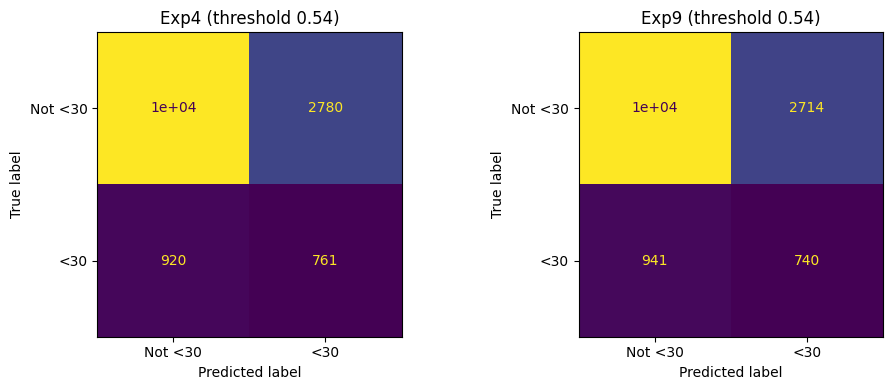

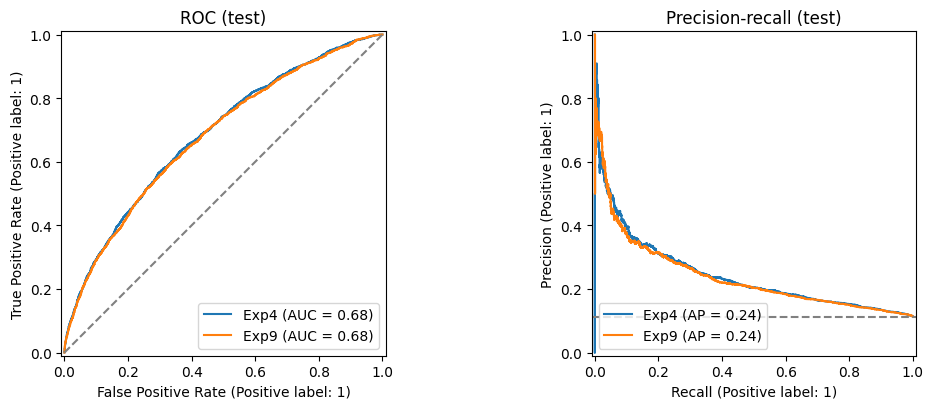

In [67]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, p) in zip(ax, test_probas.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= thr[name]).astype(int),
        display_labels=["Not <30", "<30"], ax=a, colorbar=False)
    a.set_title(name.split(" ")[0] + f" (threshold {thr[name]:.2f})")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p in test_probas.items():
    RocCurveDisplay.from_predictions(y_test, p, ax=ax[0], name=name.split(" ")[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, ax=ax[1], name=name.split(" ")[0])
ax[0].plot([0, 1], [0, 1], "--", c="grey"); ax[0].set_title("ROC (test)")
ax[1].axhline(y_test.mean(), ls="--", c="grey"); ax[1].set_title("Precision-recall (test)")
plt.tight_layout(); plt.show()

## 22. Subgroup analysis (age, race, insulin)
Does the model work equally well for everyone? Calculate the tuned LightGBM model's metrics by age, race, and insulin-use groups using the same validation-selected threshold. Groups with fewer than 30 positive cases receive undefined (NaN) metrics to avoid over-interpreting very small samples.

Recorded age-group pattern: recall is similar across the shown age bands (about 0.444–0.471), while ROC-AUC is lower for patients over 70 (0.651) than for those under 50 (0.716). Read PR-AUC alongside each group's base rate, and treat subgroup differences as signals for further review rather than definitive evidence of bias or its cause.

In [68]:
p_best = test_probas[CLASSICAL]; t_best = thr[CLASSICAL]

def group_report(masks):
    out = []
    for g, m in masks.items():
        m = np.asarray(m); yt, pp = y_test[m], p_best[m]; pred = (pp >= t_best).astype(int)
        row = {"Group": g, "n": int(m.sum()), "Positives": int(yt.sum()), "Base rate": round(yt.mean(), 3)}
        ok = yt.sum() >= 30
        row["PR-AUC"] = round(average_precision_score(yt, pp), 3) if ok else np.nan
        row["ROC-AUC"] = round(roc_auc_score(yt, pp), 3) if ok else np.nan
        row["Recall"] = round(recall_score(yt, pred), 3) if ok else np.nan
        row["Precision"] = round(precision_score(yt, pred, zero_division=0), 3) if ok else np.nan
        out.append(row)
    return pd.DataFrame(out)

age_grp = pd.cut(test_meta["age_num"], [0, 50, 70, 100], labels=["Under 50", "50-70", "Over 70"])
print("AGE");     display(group_report({g: age_grp == g for g in age_grp.cat.categories}))
print("RACE");    display(group_report({g: test_meta["race"] == g for g in test_meta["race"].value_counts().index}))
on_ins = test_meta["insulin"] != "No"
print("INSULIN"); display(group_report({"On insulin": on_ins, "Not on insulin": ~on_ins}))

AGE


,Group,n,Positives,Base rate,PR-AUC,ROC-AUC,Recall,Precision
0,Under 50,2317,238,0.103,0.287,0.716,0.471,0.251
1,50-70,5777,633,0.110,0.259,0.706,0.457,0.241
2,Over 70,6765,810,0.120,0.217,0.651,0.444,0.190


RACE


,Group,n,Positives,Base rate,PR-AUC,ROC-AUC,Recall,Precision
0,Caucasian,11129,1264,0.114,0.243,0.676,0.446,0.210
1,AfricanAmerican,2817,330,0.117,0.245,0.695,0.470,0.221
2,Unknown,320,20,0.062,NaN,NaN,NaN,NaN
3,Hispanic,307,38,0.124,0.364,0.764,0.474,0.277
4,Other,192,22,0.115,NaN,NaN,NaN,NaN
5,Asian,94,7,0.074,NaN,NaN,NaN,NaN


INSULIN


,Group,n,Positives,Base rate,PR-AUC,ROC-AUC,Recall,Precision
0,On insulin,7916,996,0.126,0.252,0.676,0.497,0.217
1,Not on insulin,6943,685,0.099,0.234,0.687,0.388,0.212


## 23. Error analysis
Who does the best model get wrong? We split the test encounters into true positives (TP), false negatives (FN: readmitted but missed), false positives (FP: flagged but not readmitted) and true negatives (TN), and compare their average characteristics. Then we look at how recall changes with the number of prior inpatient visits, a strong predictor.

Recorded result: there are 920 false negatives and 2,780 false positives, compared with 761 true positives. True positives have more prior inpatient visits on average (2.48) than false negatives (0.28), suggesting prior utilisation is an important signal and that patients with little prior inpatient history are harder to identify. The bucket table shows how recall changes with prior visits.

In [69]:
pred_best = (p_best >= t_best).astype(int)
outcome = np.select([(y_test == 1) & (pred_best == 1), (y_test == 1) & (pred_best == 0),
                     (y_test == 0) & (pred_best == 1)], ["TP", "FN", "FP"], "TN")
print(pd.Series(outcome).value_counts().to_string(), "\n")

cols = ["number_inpatient", "prior_visits", "time_in_hospital", "num_lab_procedures",
        "num_medications", "number_diagnoses", "n_meds_used", "age_num"]
display(test_meta.assign(outcome=outcome).groupby("outcome")[cols].mean().round(2).loc[["TP", "FN", "FP", "TN"]])

bucket = pd.cut(test_meta["number_inpatient"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
d = pd.DataFrame({"bucket": bucket, "y": y_test, "pred": pred_best})
display(d.groupby("bucket", observed=True).apply(
    lambda g: pd.Series({"n": len(g), "readmission rate": round(g.y.mean(), 3),
                         "recall": round(g.pred[g.y == 1].mean(), 3)}), include_groups=False))

TN    10398
FP     2780
FN      920
TP      761 



,number_inpatient,prior_visits,time_in_hospital,num_lab_procedures,num_medications,number_diagnoses,n_meds_used,age_num
outcome,,,,,,,,
TP,2.48,3.77,4.97,44.10,17.14,7.74,1.10,65.78
FN,0.28,0.82,4.48,43.69,16.11,7.60,1.24,67.32
FP,1.81,2.81,5.16,45.67,17.52,8.08,1.12,68.76
TN,0.20,0.61,4.12,41.97,15.41,7.22,1.20,64.97


,n,readmission rate,recall
bucket,,,
0,9945.0,0.083,0.163
1,2831.0,0.137,0.475
2,1105.0,0.172,0.911
3+,978.0,0.282,0.975


## 24. Feature importance (LightGBM)
Gain importance measures how much each feature improved the model's splits. One-hot columns are summed back to the original feature so the chart is readable. This shows what the model relies on, but it does not prove those features *cause* readmission.

Chart Interpretion: larger bars indicate features that contributed more to improvements in tree splits in this fitted model. Focus on the highest-ranked features and whether they align with the engineered utilisation and medication features.

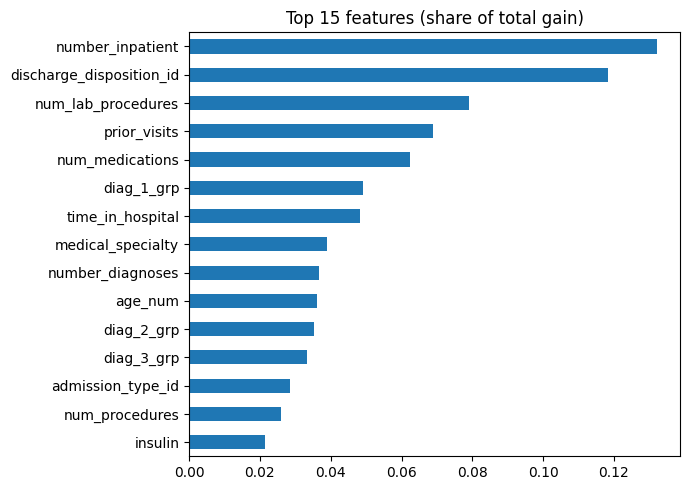

In [70]:
prep_fitted = best_lgbm.named_steps["prep"]
names = [n.split("__", 1)[1] for n in prep_fitted.get_feature_names_out()]
gain = best_lgbm.named_steps["clf"].booster_.feature_importance(importance_type="gain")

def original_feature(n):
    if n in NUM: return n
    matches = [c for c in CAT if n.startswith(c + "_")]
    return max(matches, key=len) if matches else n

imp = pd.Series(gain, index=[original_feature(n) for n in names]).groupby(level=0).sum()
imp = (imp / imp.sum()).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(7, 5), title="Top 15 features (share of total gain)")
plt.tight_layout(); plt.show()

Saving results on Google drive

In [78]:
from google.colab import drive
import shutil, os

drive.mount("/content/drive", force_remount=True)

OUT = "/content/drive/MyDrive/diabetes_readmission_outputs"
os.makedirs(OUT, exist_ok=True)

# Results tables and the LightGBM search log
pd.DataFrame(results).to_csv("results.csv", index=False)
pd.DataFrame(search.cv_results_).to_csv("lightgbm_search_results.csv", index=False)
test_results.to_csv("test_results.csv", index=False)

# TensorBoard logs (zipped into one file)
shutil.make_archive("tensorboard_logs", "zip", "logs")

files_to_save = ["results.csv", "lightgbm_search_results.csv", "test_results.csv",
                 "best_traditional_model.joblib", "best_dl_model.keras",
                 "tensorboard_logs.zip"]

for f in files_to_save:
    if os.path.exists(f):
        shutil.copy(f, OUT)
        print("saved:", f)
    else:
        print("MISSING:", f)

print("\nIn Drive:", os.listdir(OUT))

Mounted at /content/drive
saved: results.csv
saved: lightgbm_search_results.csv
saved: test_results.csv
saved: best_traditional_model.joblib
saved: best_dl_model.keras
saved: tensorboard_logs.zip

In Drive: ['results.csv', 'lightgbm_search_results.csv', 'test_results.csv', 'best_dl_model.keras', 'tensorboard_logs.zip', 'best_traditional_model.joblib']
